# Lab 4 — Image Processing

Loaded: ./mountains.jpg  shape=(512, 512)


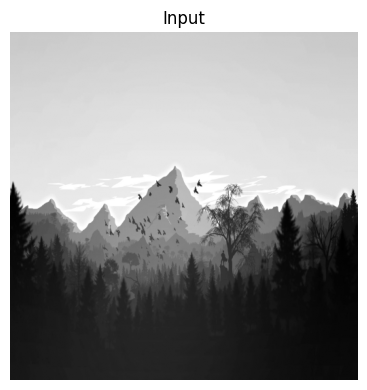

In [13]:
import numpy as np, cv2, matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift, dct

IMAGE_PATH = './mountains.jpg'
N = 512

img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
if img is None:
    print('Image not found — using synthetic fallback')
    rng = np.random.default_rng(42)
    y,x = np.mgrid[0:N,0:N]
    img = np.clip(
        80 + 60*(x/N) + 40*(y/N)
        + 50*np.sin(2*np.pi*x/64)*np.cos(2*np.pi*y/64)
        + 80*((x>100)&(x<300)&(y>100)&(y<200))
        + rng.normal(0,10,(N,N)), 0, 255).astype(np.uint8)
else:
    img = cv2.resize(img, (N,N), interpolation=cv2.INTER_AREA)
    print(f'Loaded: {IMAGE_PATH}  shape={img.shape}')

plt.figure(figsize=(4,4))
plt.imshow(img,cmap='gray'); plt.title('Input'); plt.axis('off')
plt.tight_layout(); plt.show()

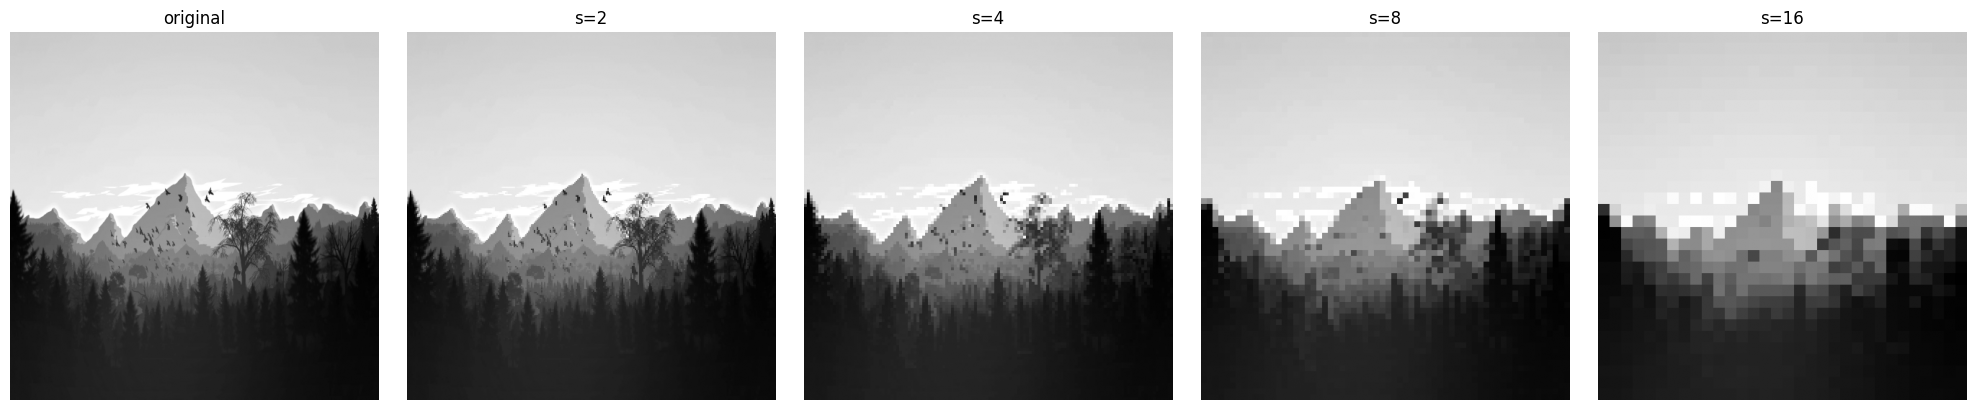

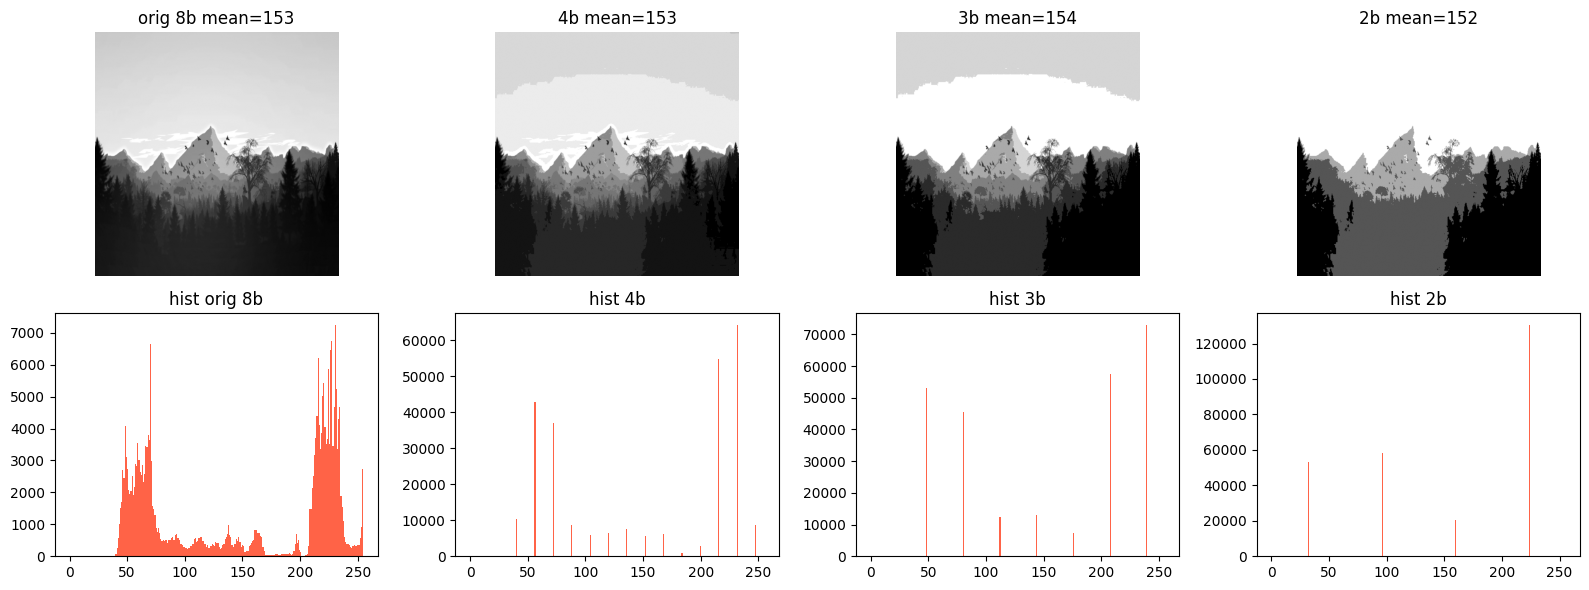

In [ ]:
def smp(im, s):
    h,w = im.shape
    return cv2.resize(im[::s,::s],(w,h),interpolation=cv2.INTER_NEAREST)

def qnt(im, L):
    st = 256/L
    b  = np.floor(im/st).astype(int)
    return np.clip(b*st+st/2, 0, 255).astype(np.uint8)

# sampling
fig,ax = plt.subplots(1,5,figsize=(20,4))
ax[0].imshow(img,cmap='gray'); ax[0].set_title('original')
for i,s in enumerate([2,4,8,16],1):
    ax[i].imshow(smp(img,s),cmap='gray'); ax[i].set_title(f's={s}')
[a.axis('off') for a in ax]; plt.tight_layout(); plt.show()

# quantization + histograms
cases = [(img,'orig 8b'),(qnt(img,16),'4b'),(qnt(img,8),'3b'),(qnt(img,4),'2b')]
fig,ax = plt.subplots(2,4,figsize=(16,6))
for c,(im,lb) in enumerate(cases):
    ax[0,c].imshow(im,cmap='gray'); ax[0,c].set_title(f'{lb} mean={im.mean():.0f}')
    ax[0,c].axis('off')
    ax[1,c].hist(im.ravel(),bins=256,range=(0,255),color='tomato')
    ax[1,c].set_title(f'hist {lb}')
plt.tight_layout(); plt.show()

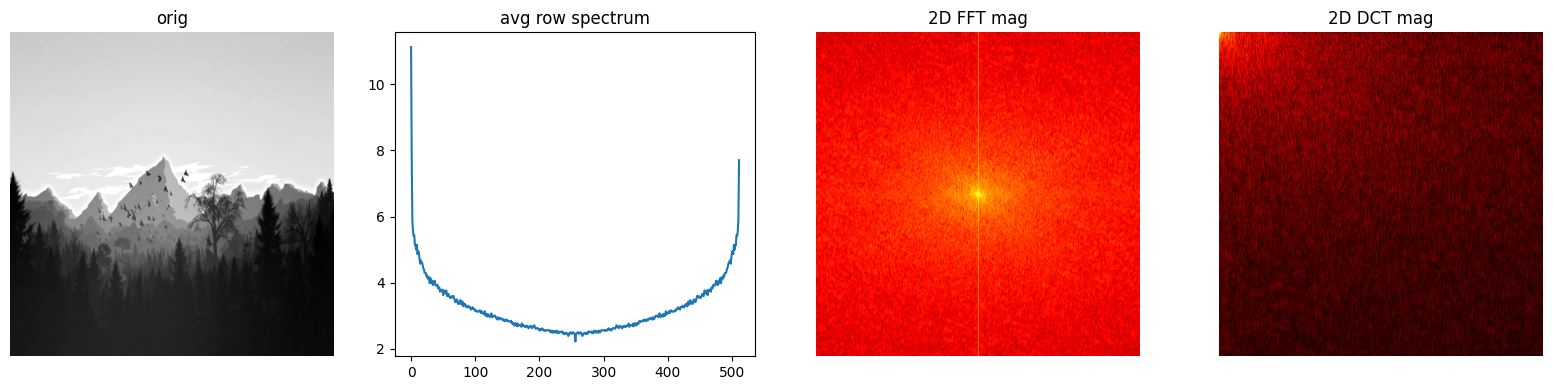

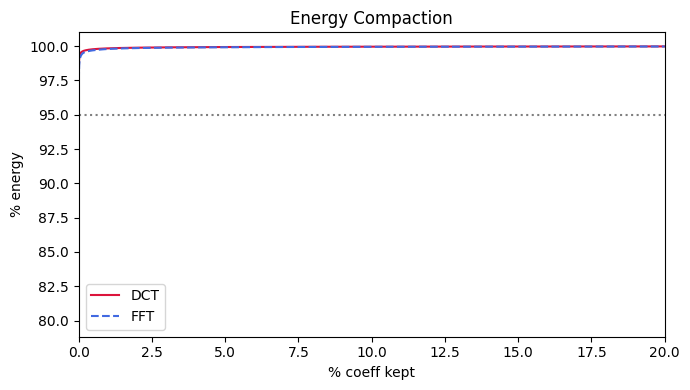

In [15]:
f = img.astype(np.float64)
Fr = np.fft.fft(f, axis=1)          # 1-D FFT rows
F2 = np.fft.fft(Fr, axis=0)         # 1-D FFT cols → 2-D FFT
spec = np.log1p(np.abs(fftshift(F2)))
D = dct(dct(f,axis=1,norm='ortho'),axis=0,norm='ortho')  # 2-D DCT

fig,ax = plt.subplots(1,4,figsize=(16,4))
ax[0].imshow(img,cmap='gray'); ax[0].set_title('orig'); ax[0].axis('off')
ax[1].plot(np.log1p(np.abs(Fr)).mean(0)); ax[1].set_title('avg row spectrum')
ax[2].imshow(spec,cmap='hot'); ax[2].set_title('2D FFT mag'); ax[2].axis('off')
ax[3].imshow(np.log1p(np.abs(D)),cmap='hot'); ax[3].set_title('2D DCT mag'); ax[3].axis('off')
plt.tight_layout(); plt.show()

# energy compaction
dp = np.sort(D.ravel()**2)[::-1]
fp = np.sort(np.abs(F2.ravel())**2)[::-1]
n  = np.arange(1,len(dp)+1)/len(dp)*100
plt.figure(figsize=(7,4))
plt.plot(n,np.cumsum(dp)/dp.sum()*100,label='DCT',c='crimson')
plt.plot(n,np.cumsum(fp)/fp.sum()*100,label='FFT',c='royalblue',ls='--')
plt.axhline(95,c='gray',ls=':'); plt.xlim(0,20)
plt.xlabel('% coeff kept'); plt.ylabel('% energy')
plt.legend(); plt.title('Energy Compaction'); plt.tight_layout(); plt.show()

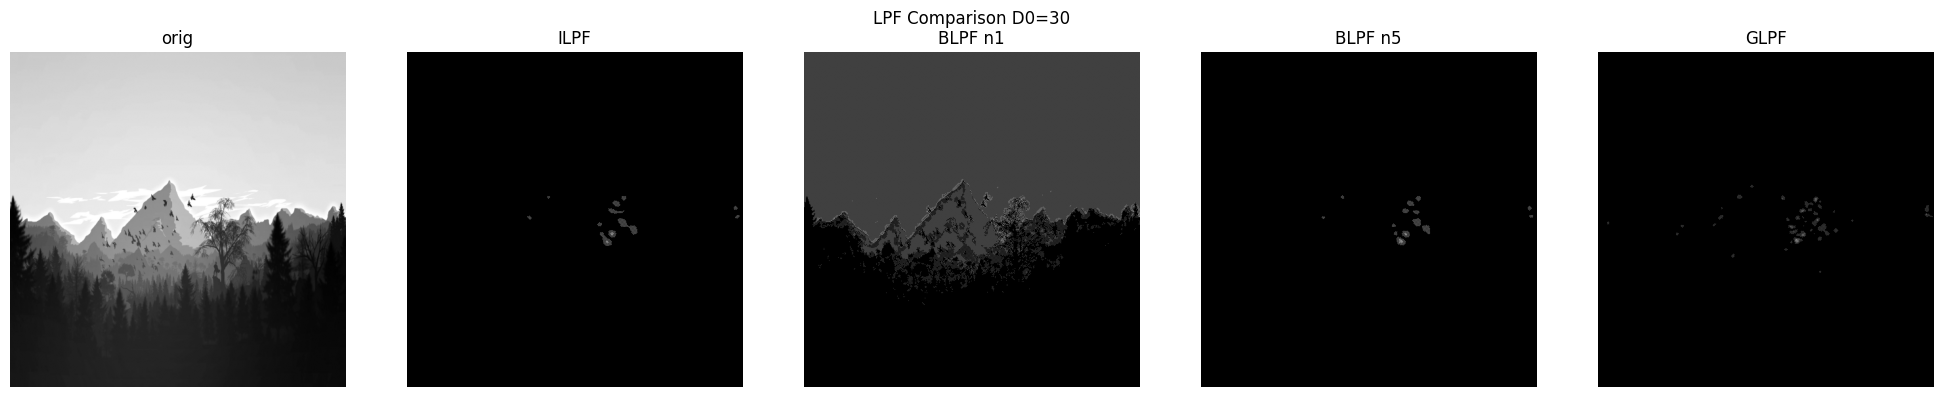

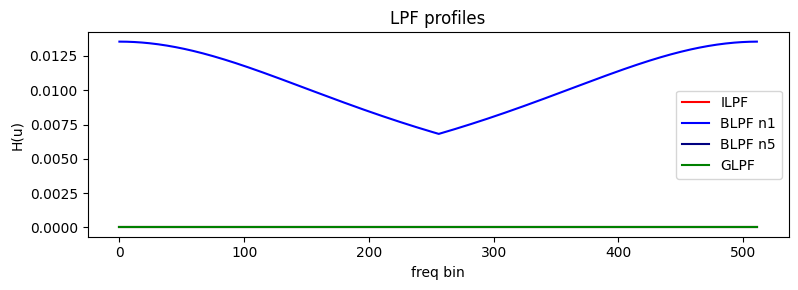

In [16]:
def Dm(sh):
    u=np.fft.fftfreq(sh[0])*sh[0]; v=np.fft.fftfreq(sh[1])*sh[1]
    U,V=np.meshgrid(u,v,indexing='ij')
    return np.sqrt(U**2+V**2)

def flt(im,H):
    F=fftshift(fft2(im.astype(float)))
    return np.clip(np.real(ifft2(ifftshift(F*H))),0,255).astype(np.uint8)

D0=30; D=Dm(img.shape)
Hi=(D<=D0).astype(float)          # ILPF
Hb1=1/(1+(D/D0)**2)               # BLPF n=1
Hb5=1/(1+(D/D0)**10)              # BLPF n=5
Hg=np.exp(-D**2/(2*D0**2))        # GLPF

lbls=['orig','ILPF','BLPF n1','BLPF n5','GLPF']
imgs=[img,flt(img,Hi),flt(img,Hb1),flt(img,Hb5),flt(img,Hg)]
fig,ax=plt.subplots(1,5,figsize=(20,4))
for a,im,lb in zip(ax,imgs,lbls):
    a.imshow(im,cmap='gray'); a.set_title(lb); a.axis('off')
plt.suptitle(f'LPF Comparison D0={D0}'); plt.tight_layout(); plt.show()

# transfer function profiles
m=img.shape[0]//2
plt.figure(figsize=(8,3))
for H,lb,c in [(Hi,'ILPF','r'),(Hb1,'BLPF n1','b'),(Hb5,'BLPF n5','navy'),(Hg,'GLPF','g')]:
    plt.plot(H[m,:],label=lb,c=c)
plt.xlabel('freq bin'); plt.ylabel('H(u)'); plt.legend(); plt.title('LPF profiles')
plt.tight_layout(); plt.show()

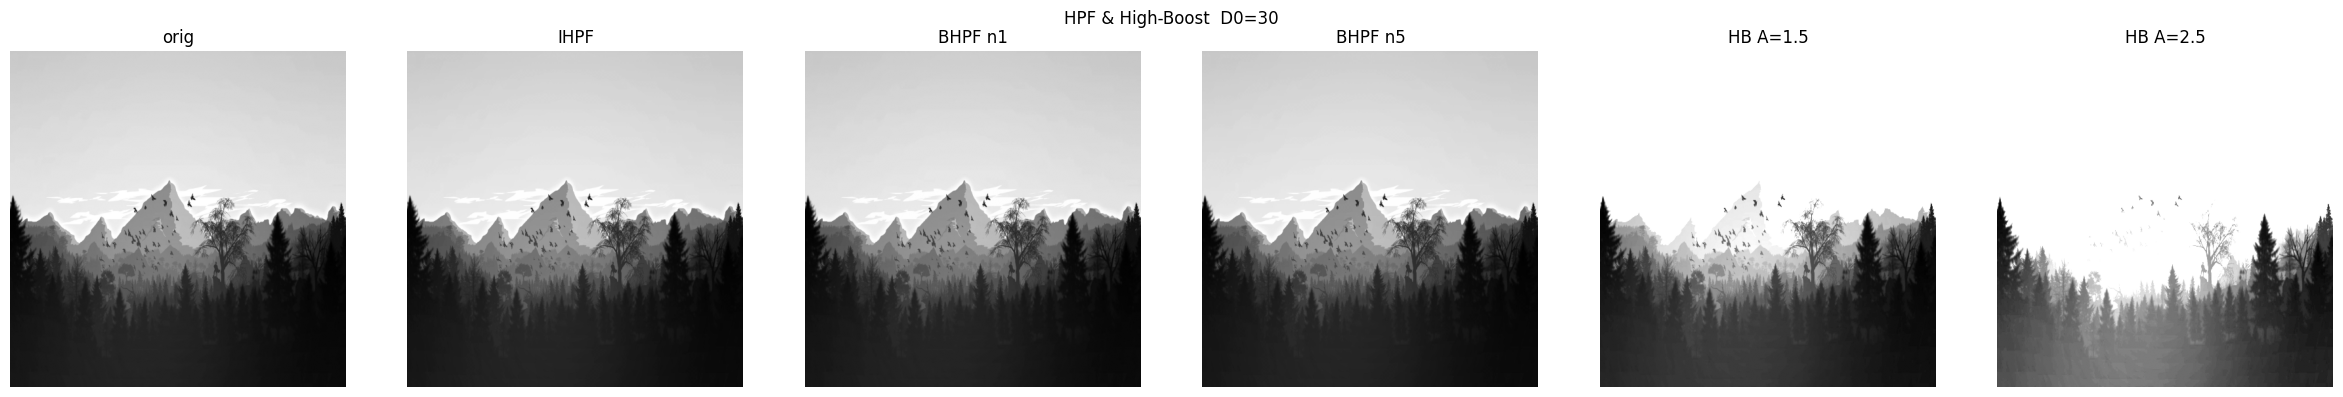

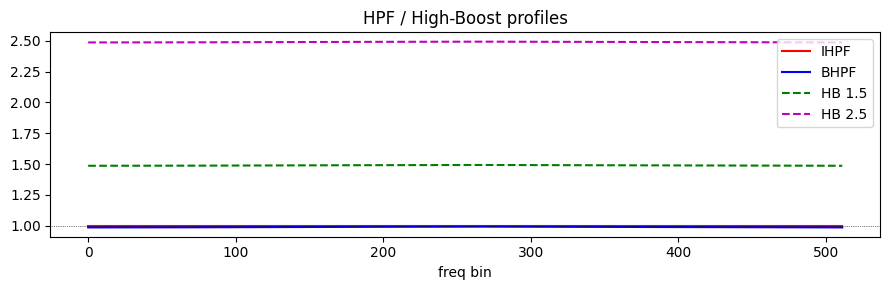

In [17]:
Hih=1-Hi; Hbh=1-Hb1; Hbh5=1-Hb5   # HPFs
Hhb15=1.5-Hb1; Hhb25=2.5-Hb1       # High-Boost A=1.5, 2.5

lbls2=['orig','IHPF','BHPF n1','BHPF n5','HB A=1.5','HB A=2.5']
imgs2=[img,flt(img,Hih),flt(img,Hbh),flt(img,Hbh5),flt(img,Hhb15),flt(img,Hhb25)]
fig,ax=plt.subplots(1,6,figsize=(24,4))
for a,im,lb in zip(ax,imgs2,lbls2):
    a.imshow(im,cmap='gray'); a.set_title(lb); a.axis('off')
plt.suptitle(f'HPF & High-Boost  D0={D0}'); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,3))
for H,lb,c,ls in [(Hih,'IHPF','r','-'),(Hbh,'BHPF','b','-'),
                  (Hhb15,'HB 1.5','g','--'),(Hhb25,'HB 2.5','m','--')]:
    plt.plot(H[m,:],label=lb,c=c,ls=ls)
plt.axhline(1,c='k',lw=0.5,ls=':'); plt.legend(); plt.xlabel('freq bin')
plt.title('HPF / High-Boost profiles'); plt.tight_layout(); plt.show()

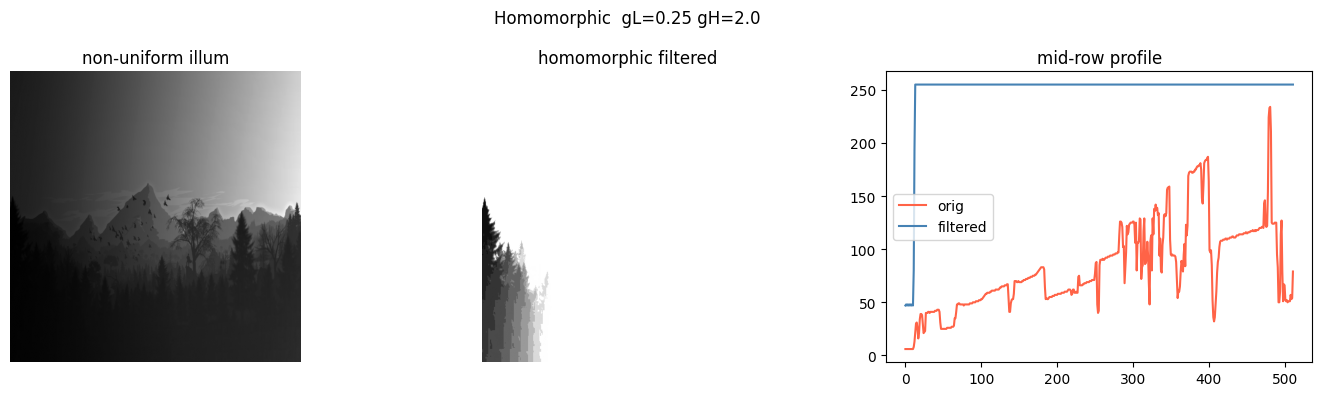

dark  left/right mean: 28.9 / 116.7
fixed left/right mean: 213.9 / 255.0


In [18]:
H_sz,W_sz = img.shape
_,xg = np.mgrid[0:H_sz,0:W_sz]
dark = np.clip(img*(0.15+0.85*(xg/W_sz)**1.5),1,255).astype(np.uint8)

# Homomorphic filter
gL,gH,D0h = 0.25, 2.0, 30
Dh = Dm(dark.shape)                         
z  = np.log1p(dark.astype(float))
Z  = fftshift(fft2(z))
H_hm = (gH-gL)*(1 - 1/(1+(Dh/D0h)**4)) + gL 
g    = np.real(ifft2(ifftshift(Z*H_hm)))
out  = np.clip(np.expm1(g),0,255).astype(np.uint8)

fig,ax=plt.subplots(1,3,figsize=(14,4))
ax[0].imshow(dark,cmap='gray'); ax[0].set_title('non-uniform illum'); ax[0].axis('off')
ax[1].imshow(out, cmap='gray'); ax[1].set_title('homomorphic filtered'); ax[1].axis('off')
r=H_sz//2
ax[2].plot(dark[r,:],label='orig',c='tomato')
ax[2].plot(out[r,:], label='filtered',c='steelblue')
ax[2].set_title('mid-row profile'); ax[2].legend()
plt.suptitle(f'Homomorphic  gL={gL} gH={gH}'); plt.tight_layout(); plt.show()

print(f'dark  left/right mean: {dark[:,:W_sz//4].mean():.1f} / {dark[:,3*W_sz//4:].mean():.1f}')
print(f'fixed left/right mean: {out[:,:W_sz//4].mean():.1f} / {out[:,3*W_sz//4:].mean():.1f}')